In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

In [2]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 10, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.zeros(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y

In [3]:
torch.manual_seed(42)
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')

# model = bsplines(10,3)
model = bsplines(10,6)
# model.coeffs.to(device)


In [4]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

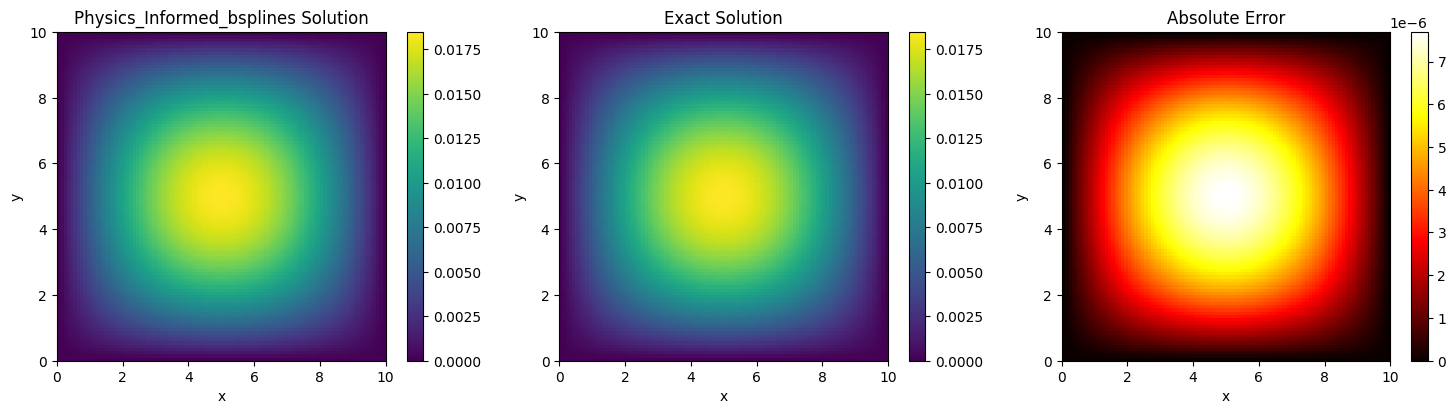

In [9]:
def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(np.pi**4*D*(1/a**2+1/b**2)**2)*np.sin(x*np.pi/a)*np.sin(y*np.pi/b)

    return u_ex
x = y = np.linspace(0, 10, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)
u_ex = u_exact(Xg, Yg, D, a, b, p_0)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_ex, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_ex)
im2 = axs[2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.savefig('Kirchoff.pdf',dpi=300)
plt.show()

DC have already been imposed to zero. Now we want to impose Neuman boundary condition:

$m_x(x,y)=-D(\theta_x^2u+\nu\theta_y^2u)$
$\\ m_y(x,y)=-D(\nu\theta_x^2u+\theta_y^2u)$
$\\ m_x(0,y) = m_x(10,y)=m_y(x,0)=m_y(x,10)=0$

Train the interior points 
$\\ res = \nabla^4u(x,y)-\frac{p(x,y)}{D} = \theta^4w/\theta x^4+2\theta^4w/\theta x^2\theta y^2+\theta^4w/\theta y^4-\frac{p(x,y)}{D}$



In [5]:
def generate_points(n_interior, n_boundary):
    # Interior points
    torch.manual_seed(42)
    xy_in = torch.rand(n_interior, 2)*10
    # Boundary points on [0,10]^2
    lin = torch.linspace(0, 10, n_boundary).unsqueeze(1)
    zero = torch.zeros_like(lin)
    one = torch.ones_like(lin)*10
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b_h = torch.cat([b1, b2], dim=0)
    xy_b_v = torch.cat([b3, b4], dim=0)
    return xy_in, xy_b_h, xy_b_v 

In [6]:
def boundary_loss1(model, X_b_v):
    # X_b_v.requires_grad_(True)
    u = model.forward(X_b_v)
    grads = torch.autograd.grad(u, X_b_v, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X_b_v, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X_b_v, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    m_x = -D*(u_xx+nu*u_yy)
    
    
    return torch.mean(m_x**2)

In [7]:
def boundary_loss2(model, X_b_h):
    # X_b_h.requires_grad_(True)
    u = model.forward(X_b_h)
    grads = torch.autograd.grad(u, X_b_h, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X_b_h, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X_b_h, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    m_y = -D*(nu*u_xx+u_yy)
    
    
    return torch.mean(m_y**2)

In [8]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

In [9]:
def source(X):

    p = p_0*torch.sin(np.pi*X[:,0]/a)*torch.sin(np.pi*X[:,1]/b)

    return p

In [10]:
X_in, X_b_h, X_b_v = generate_points(10000, 5000)
X_in.requires_grad_(True)
X_b_v.requires_grad_(True)
X_b_h.requires_grad_(True)

tensor([[0.0000e+00, 0.0000e+00],
        [2.0004e-03, 0.0000e+00],
        [4.0008e-03, 0.0000e+00],
        ...,
        [9.9960e+00, 1.0000e+01],
        [9.9980e+00, 1.0000e+01],
        [1.0000e+01, 1.0000e+01]], requires_grad=True)

In [11]:
x = y = np.linspace(0, 10, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
XYt = XY_torch*0.999+0.0001
XYt.requires_grad_(True)



tensor([[1.0000e-04, 1.0000e-04],
        [1.0101e-01, 1.0000e-04],
        [2.0192e-01, 1.0000e-04],
        ...,
        [9.7883e+00, 9.9901e+00],
        [9.8892e+00, 9.9901e+00],
        [9.9901e+00, 9.9901e+00]], requires_grad=True)

In [12]:
XYt.shape

torch.Size([10000, 2])

In [15]:
# Manual scaling and lr reducement
epochs = 100
learning_rate=1e-8

# torch.manual_seed(42)
optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)



In [ ]:
loss_vec=[]

In [16]:
epochs = 200


for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(XYt)
    # First derivatives
    grads = torch.autograd.grad(u, XYt, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]

    # Second derivatives (Laplacian)
    grads2_x = torch.autograd.grad(u_x, XYt, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    grads2_y = torch.autograd.grad(u_y, XYt, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]

    u_xx = grads2_x[:, 0]
    u_xy = grads2_x[:, 1]
    u_yy = grads2_y[:, 1]
    u_yx = grads2_y[:, 0]  # should equal u_xy

    laplacian_u = u_xx + u_yy

    # Now compute ∇²(∇²u) = Laplacian of laplacian_u
    laplacian_u_grad = torch.autograd.grad(laplacian_u, XYt, grad_outputs=torch.ones_like(laplacian_u), create_graph=True)[0]
    laplacian_u_x = laplacian_u_grad[:, 0]
    laplacian_u_y = laplacian_u_grad[:, 1]

    laplacian_u_xx = torch.autograd.grad(laplacian_u_x, XYt, grad_outputs=torch.ones_like(laplacian_u_x), create_graph=True)[0][:, 0]
    laplacian_u_yy = torch.autograd.grad(laplacian_u_y, XYt, grad_outputs=torch.ones_like(laplacian_u_y), create_graph=True)[0][:, 1]

    p = source(XYt)
    # Residual loss
    res = laplacian_u_xx + laplacian_u_yy - p/D
    
    loss_res = torch.mean(res**2)

    loss_b1 = boundary_loss1(model, X_b_v)
    loss_b2 = boundary_loss2(model, X_b_h)

    loss = 100*loss_res+loss_b1+loss_b2
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/200], Loss: 1.2722444807877764e-05


KeyboardInterrupt: 

In [195]:
#Save model trainable parameters(22300 with varying lambda but mainly 100 in res only. We can try to run everything with fixed lambda 100)
params = { 'coeffs_trainable': model.coeffs }
torch.save(params, './results/Kirchoff/model_bsplines.pth')

In [198]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/Kirchoff/bsplines_loss.npy',loss_vec_npy)

In [5]:
# Load model trainable parameters for PI-Tp-BsN
model_s = bsplines(10,6)
loaded_params = torch.load('./results/Kirchoff/model_bsplines.pth')
model_s.coeffs = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_76140\978917227.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/Kirchoff/model_bspl

In [6]:
loss_bsplines_s = np.load('./results/Kirchoff/bsplines_loss.npy')

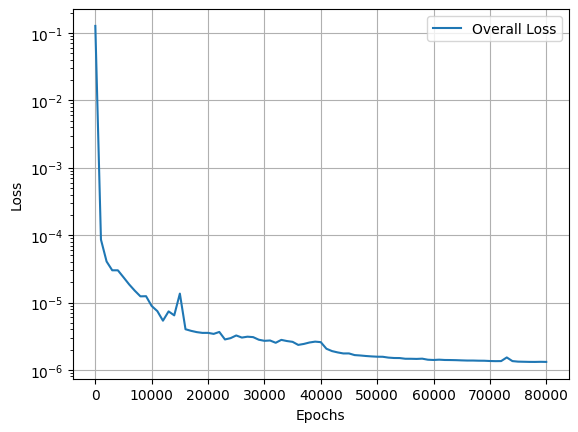

In [7]:

# These data are given by Ivan by running relobralo
args_summary = np.load("./results/Kirchoff/args_summary.npy")

l0 = (args_summary[:,9])

l1 = (args_summary[:,10])

l2 = (args_summary[:,11])

l3 = (args_summary[:,12])

l4 = (args_summary[:,13])

l5 = (args_summary[:,14])

l6 = (args_summary[:,15])

l7 = (args_summary[:,16])

l8 = (args_summary[:,17])




# PINN loss relobralo
loss_pinn = l0+l1+l2+l3+l4+l5+l6+l7+l8





plt.semilogy(np.linspace(0,80000, 81),loss_pinn,
label='Overall Loss')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.grid()

plt.show()

In [8]:
# data from ivan by running relobralo
import numpy as np
import matplotlib.pyplot as plt


w_pred = np.load("./results/Kirchoff/w_pred_100.npy")
w_pred = w_pred.reshape(100,100)

w_real = np.load("./results/Kirchoff/w_real_100.npy")
w_real = w_real.reshape(100,100)



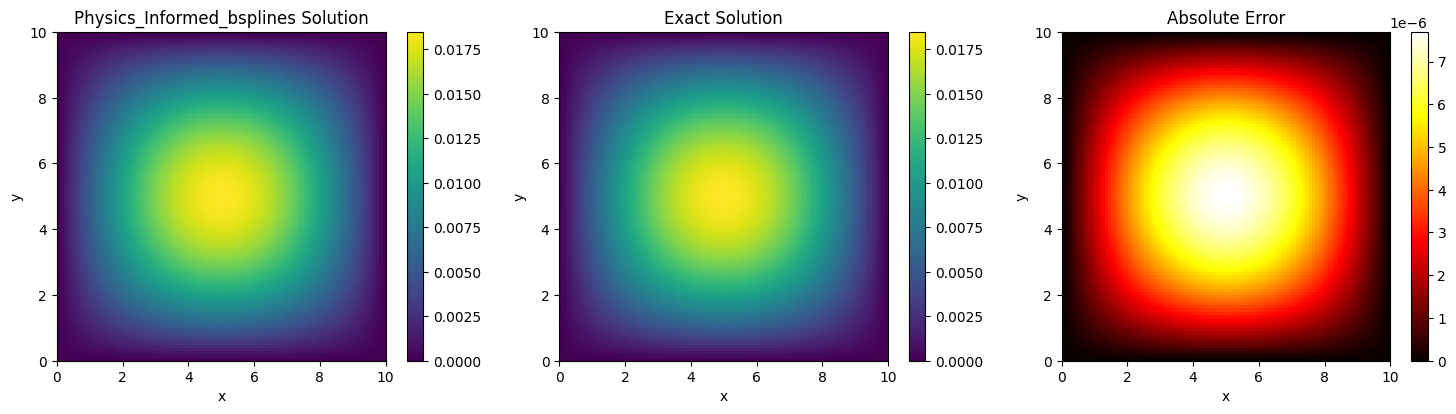

In [9]:
# Test grid  and plot

def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(np.pi**4*D*(1/a**2+1/b**2)**2)*np.sin(x*np.pi/a)*np.sin(y*np.pi/b)

    return u_ex
x = y = np.linspace(0, 10, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)
u_ex = u_exact(Xg, Yg, D, a, b, p_0)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_ex)
im2 = axs[2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
# plt.savefig('Kirchoff.pdf',dpi=300)
plt.show()

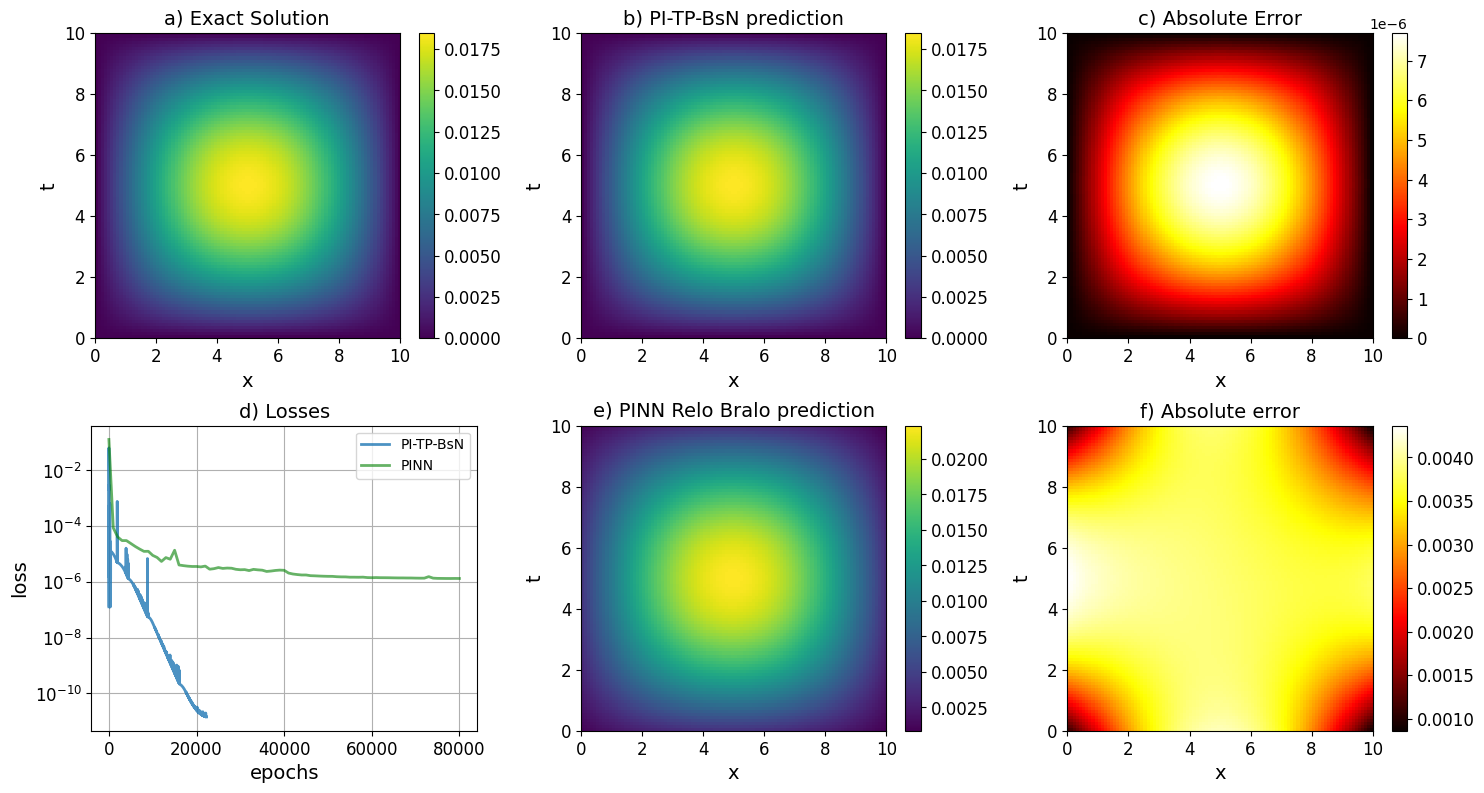

In [10]:
# Exact solution
fig, axs = plt.subplots(2, 3, figsize=(15, 8))

im0 = axs[0,0].imshow(u_ex, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0,0].set_title("a) Exact Solution",fontsize=14)
axs[0,0].set_xlabel("x",fontsize=14)
axs[0,0].set_ylabel("t",fontsize=14)
axs[0,0].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im0, ax=axs[0,0])
cbar.ax.tick_params(labelsize=12) 

# B-splines solution
im1 = axs[0, 1].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0,1].set_title("b) PI-TP-BsN prediction",fontsize=14)
axs[0,1].set_xlabel("x",fontsize=14)
axs[0,1].set_ylabel("t",fontsize=14)
axs[0,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im1, ax=axs[0, 1])
cbar.ax.tick_params(labelsize=12) 

# Absolute error
error = np.abs(u_pred - u_ex)
im2 = axs[0, 2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[0,2].set_title("c) Absolute Error",fontsize=14)
axs[0,2].set_xlabel("x",fontsize=14)
axs[0,2].set_ylabel("t",fontsize=14)
axs[0,2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im2, ax=axs[0, 2])
cbar.ax.tick_params(labelsize=12) 

# Losses
x_a = np.arange(len(loss_bsplines_s))
x_b = np.linspace(0,80000, 81)
axs[1, 0].plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
axs[1, 0].plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
axs[1, 0].legend()
axs[1, 0].set_yscale('log')
axs[1,0].set_title("d) Losses",fontsize=14)
axs[1,0].set_xlabel("epochs",fontsize=14)
axs[1,0].set_ylabel("loss",fontsize=14)
axs[1,0].tick_params(axis='both', labelsize=12)
axs[1,0].grid(True)
# cbar = fig.colorbar(im3, ax=axs[1, 0])
# cbar.ax.tick_params(labelsize=12) 

# Absolute error
im4 = axs[1, 1].imshow(w_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[1,1].set_title("e) PINN Relo Bralo prediction",fontsize=14)
axs[1,1].set_xlabel("x",fontsize=14)
axs[1,1].set_ylabel("t",fontsize=14)
axs[1,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im4, ax=axs[1, 1])
cbar.ax.tick_params(labelsize=12) 

# Exact solution
error = np.abs(w_pred - u_ex)
im5 = axs[1, 2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[1, 2].set_title("f) Absolute error",fontsize=14)
axs[1, 2].set_xlabel("x",fontsize=14)
axs[1, 2].set_ylabel("t",fontsize=14)
axs[1, 2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im5, ax=axs[1, 2])
cbar.ax.tick_params(labelsize=12) 


# for ax in axs:
#     ax.set_xlabel("x",fontsize=14)
#     ax.set_ylabel("y",fontsize=14)
#     ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
# fig.savefig("Kirchoff.pdf", dpi=300)
plt.show()

In [12]:
np.sqrt(np.sum((u_pred - u_ex)**2))/np.sqrt(np.sum(u_ex**2))


0.00041115102387778913

In [13]:
np.sqrt(np.sum((w_pred - w_real)**2))/np.sqrt(np.sum(w_real**2))


0.3898168